In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import files

# Prompt user to upload a file
uploaded = files.upload()

# List the uploaded files
for filename in uploaded.keys():
    print(f'User uploaded file "{filename}" with length {len(uploaded[filename])} bytes')


Saving abcnews-date-text.csv to abcnews-date-text (1).csv
User uploaded file "abcnews-date-text (1).csv" with length 63807429 bytes


In [ ]:
from google.colab import files
import pandas as pd

# Upload the CSV file
uploaded = files.upload()

# Load the CSV into a DataFrame
df = pd.read_csv("/content/sentiment_annotated_with_texts.csv")
df.head()


Saving sentiment_annotated_with_texts.csv to sentiment_annotated_with_texts (1).csv


,published_at,ticker,true_sentiment,title,author,url,source,text,finbert_sentiment,finbert_sent_score
0,2023-01-12 07:47:00,EURCHF,Positive,Euro to benefit from the ECBs pronounced hawki...,FXStreet Insights Team,https://www.fxstreet.com/news/euro-to-benefit-...,FX Street,The Euro was able to appreciate particularly s...,Positive,0.85
1,2023-01-12 10:34:00,EURCHF,Positive,EURCHF Trend higher may remain in place – ING,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-trend-hi...,FX Street,EUR/CHF yesterday broke above 1.00. Economists...,Positive,0.51
2,2023-01-12 11:40:00,EURCHF,Neutral,Does a jump in EURCHF point to a break above 1...,FXStreet Insights Team,https://www.fxstreet.com/news/does-a-jump-in-e...,FX Street,EUR/CHF vaults parity for the first time since...,Neutral,0.37
3,2023-01-12 15:32:00,EURCHF,Positive,EURCHF could extend its advance back to levels...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-could-ex...,FX Street,EUR/CHF climbs back above parity. Economists a...,Positive,0.64
4,2023-01-13 11:37:00,EURCHF,Positive,EURCHF to head higher towards 10130 and projec...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-to-head-...,FX Street,EUR/CHF has broken out above the sideways rang...,Positive,0.83


In [ ]:
import pandas as pd

df = pd.read_csv("sentiment_annotated_with_texts (1).csv")
df.head()


,published_at,ticker,true_sentiment,title,author,url,source,text,finbert_sentiment,finbert_sent_score
0,2023-01-12 07:47:00,EURCHF,Positive,Euro to benefit from the ECBs pronounced hawki...,FXStreet Insights Team,https://www.fxstreet.com/news/euro-to-benefit-...,FX Street,The Euro was able to appreciate particularly s...,Positive,0.85
1,2023-01-12 10:34:00,EURCHF,Positive,EURCHF Trend higher may remain in place – ING,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-trend-hi...,FX Street,EUR/CHF yesterday broke above 1.00. Economists...,Positive,0.51
2,2023-01-12 11:40:00,EURCHF,Neutral,Does a jump in EURCHF point to a break above 1...,FXStreet Insights Team,https://www.fxstreet.com/news/does-a-jump-in-e...,FX Street,EUR/CHF vaults parity for the first time since...,Neutral,0.37
3,2023-01-12 15:32:00,EURCHF,Positive,EURCHF could extend its advance back to levels...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-could-ex...,FX Street,EUR/CHF climbs back above parity. Economists a...,Positive,0.64
4,2023-01-13 11:37:00,EURCHF,Positive,EURCHF to head higher towards 10130 and projec...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-to-head-...,FX Street,EUR/CHF has broken out above the sideways rang...,Positive,0.83


In [ ]:
# Check missing values
df.isnull().sum()

# Drop rows with missing text or sentiment
df = df.dropna(subset=['text', 'true_sentiment'])

# Basic stats
print(df['true_sentiment'].value_counts())


true_sentiment
Neutral     815
Positive    767
Negative    709
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Prepare text and labels
X = df['text']
y = df['true_sentiment']

# TF-IDF vectorizer
vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = vectorizer.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

# Train classifier
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

    Negative       0.56      0.57      0.56       140
     Neutral       0.55      0.52      0.54       170
    Positive       0.50      0.51      0.50       149

    accuracy                           0.53       459
   macro avg       0.53      0.54      0.53       459
weighted avg       0.53      0.53      0.53       459



In [ ]:
# Basic accuracy of FinBERT vs human annotation
accuracy = (df['true_sentiment'] == df['finbert_sentiment']).mean()
print(f"FinBERT vs Human Sentiment Accuracy: {accuracy:.2%}")


FinBERT vs Human Sentiment Accuracy: 56.18%


<Axes: title={'center': 'Sentiment Over Time'}, xlabel='date'>

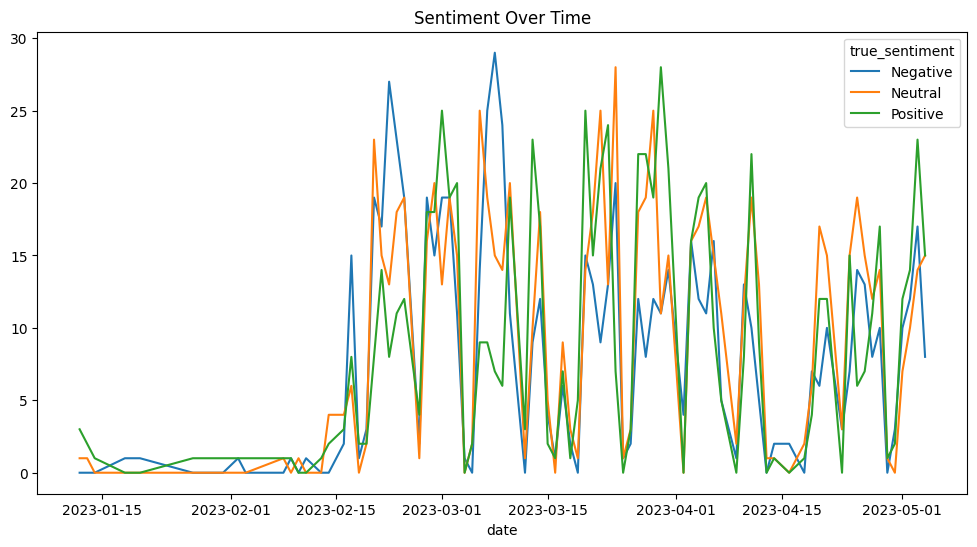

In [ ]:
df['published_at'] = pd.to_datetime(df['published_at'])
df['date'] = df['published_at'].dt.date

daily_sentiment = df.groupby(['date', 'true_sentiment']).size().unstack(fill_value=0)
daily_sentiment.plot(kind='line', figsize=(12,6), title="Sentiment Over Time")


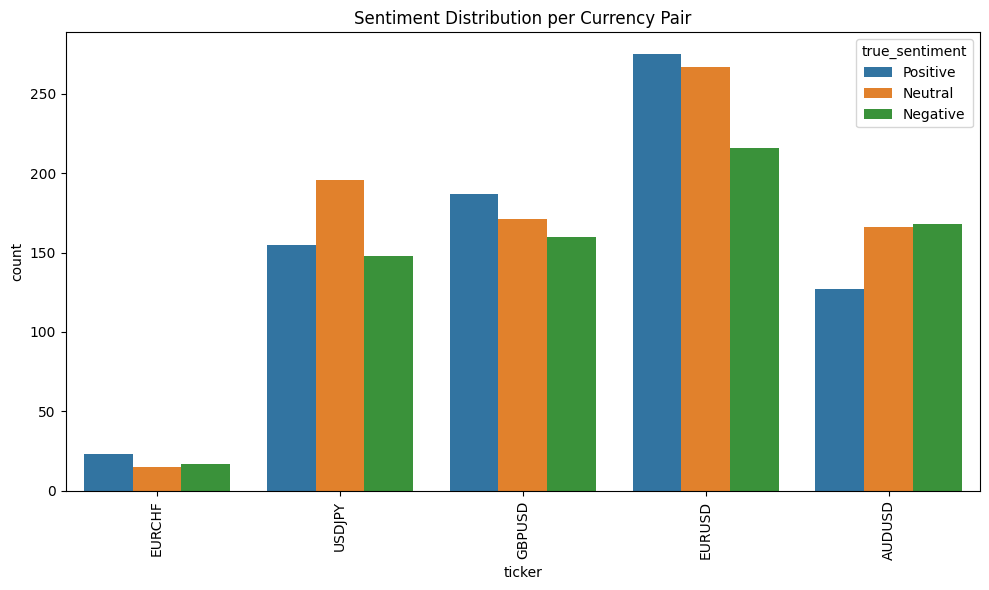

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.countplot(data=df, x='ticker', hue='true_sentiment')
plt.xticks(rotation=90)
plt.title("Sentiment Distribution per Currency Pair")
plt.tight_layout()
plt.show()


In [ ]:
!pip install transformers datasets


In [ ]:
import pandas as pd

# Load your CSV (make sure the filename matches your uploaded file)
df = pd.read_csv("sentiment_annotated_with_texts (1).csv")

# Keep only needed columns and drop NaNs
df = df.dropna(subset=['text', 'true_sentiment'])

# Map sentiment labels to numeric IDs
label_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
df['label'] = df['true_sentiment'].map(label_map)

print(df['label'].value_counts())


label
1    815
2    767
0    709
Name: count, dtype: int64


In [ ]:
from datasets import Dataset

dataset = Dataset.from_pandas(df[['text', 'label']])


In [ ]:
split = dataset.train_test_split(test_size=0.2, seed=42)
train_dataset = split['train']
test_dataset = split['test']


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "yiyanghkust/finbert-tone"  # FinBERT pretrained model

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/439M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/439M [00:00<?, ?B/s]

In [ ]:
def tokenize_function(examples):
    return tokenizer(examples['text'], truncation=True, padding='max_length', max_length=128)

train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)


Map:   0%|          | 0/1832 [00:00<?, ? examples/s]

Map:   0%|          | 0/459 [00:00<?, ? examples/s]

In [ ]:
train_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
test_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])


In [ ]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir='./finbert-finetuned-forex',
    eval_strategy="epoch", # Changed from evaluation_strategy
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    save_strategy="epoch",
    logging_dir='./logs',
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy"
)

In [ ]:
import numpy as np
from datasets import load_metric

metric = load_metric("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)  # Get predicted class
    return metric.compute(predictions=predictions, references=labels)


/tmp/ipython-input-18-924935240.py:4: FutureWarning: load_metric is deprecated and will be removed in the next major version of datasets. Use 'evaluate.load' instead, from the new library 🤗 Evaluate: https://huggingface.co/docs/evaluate
  metric = load_metric("accuracy")


In [ ]:
!pip install evaluate
import evaluate
import numpy as np

metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.1 MB/s eta 0:00:00


In [ ]:
import evaluate
import numpy as np

metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)


In [ ]:
model.save_pretrained("./finbert-forex-finetuned")
tokenizer.save_pretrained("./finbert-forex-finetuned")


('./finbert-forex-finetuned/tokenizer_config.json',
 './finbert-forex-finetuned/special_tokens_map.json',
 './finbert-forex-finetuned/vocab.txt',
 './finbert-forex-finetuned/added_tokens.json',
 './finbert-forex-finetuned/tokenizer.json')

In [ ]:
from transformers import pipeline

sentiment_pipeline = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

example_text = "EUR/USD shows signs of bullish momentum amid ECB policy uncertainty."

print(sentiment_pipeline(example_text))


Device set to use cpu


[{'label': 'Positive', 'score': 0.9999880790710449}]


In [ ]:
import pandas as pd
from transformers import pipeline

# Load the dataset
df = pd.read_csv("/content/abcnews-date-text.csv")
df = df.dropna(subset=['headline_text'])  # Clean

# Load your fine-tuned model
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_dir = "./finbert-forex-finetuned"  # Use your saved model path
tokenizer = AutoTokenizer.from_pretrained(model_dir)
model = AutoModelForSequenceClassification.from_pretrained(model_dir)

# Build a pipeline
sentiment_pipeline = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

# Predict on a sample (or full) batch of headlines
sample = df['headline_text'].sample(10).tolist()
predictions = sentiment_pipeline(sample)

# Combine results
for text, pred in zip(sample, predictions):
    print(f"📰 {text}\n→ Sentiment: {pred['label']} (Confidence: {pred['score']:.2f})\n")


Device set to use cpu


📰 virtual reality trial ahead of fire season in south australia
→ Sentiment: Positive (Confidence: 0.82)

📰 farmers prepare for ec funding
→ Sentiment: Neutral (Confidence: 1.00)

📰 the sunday inquisition august 10
→ Sentiment: Neutral (Confidence: 1.00)

📰 news csg reax
→ Sentiment: Neutral (Confidence: 1.00)

📰 rosetta spacecraft on final approach to comet landing
→ Sentiment: Neutral (Confidence: 1.00)

📰 milne's lawyer wants access to police notes
→ Sentiment: Neutral (Confidence: 1.00)

📰 needle found in mandarin amid sa fruit contamination incidents
→ Sentiment: Negative (Confidence: 0.99)

📰 nrn prawn plan
→ Sentiment: Neutral (Confidence: 1.00)

📰 tiger woods dominates presidents cup day three
→ Sentiment: Neutral (Confidence: 1.00)

📰 how long does it take to lose fitness
→ Sentiment: Neutral (Confidence: 0.73)



In [ ]:
# Run prediction on the entire dataset (can take a few minutes on CPU)
df['predicted_sentiment'] = df['headline_text'].apply(lambda x: sentiment_pipeline(x)[0]['label'])
df['confidence'] = df['headline_text'].apply(lambda x: sentiment_pipeline(x)[0]['score'])


In [ ]:
df.to_csv("abcnews_with_sentiment.csv", index=False)


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='predicted_sentiment')
plt.title("Sentiment Distribution in ABC News Headlines")
plt.show()


In [ ]:
df['publish_date'] = pd.to_datetime(df['publish_date'], format='%Y%m%d')

# Group by date
daily_sentiment = df.groupby([df['publish_date'].dt.to_period("M"), 'predicted_sentiment']).size().unstack(fill_value=0)
daily_sentiment.plot(kind='line', figsize=(12,6), title="Monthly Sentiment Trends in ABC News")


In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/abcnews-date-text.csv')

# Preview the dataset
print(df.head())
print(df.info())
print(df['headline_text'].sample(5))


   publish_date                                      headline_text
0      20030219  aba decides against community broadcasting lic...
1      20030219     act fire witnesses must be aware of defamation
2      20030219     a g calls for infrastructure protection summit
3      20030219           air nz staff in aust strike for pay rise
4      20030219      air nz strike to affect australian travellers
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1244184 entries, 0 to 1244183
Data columns (total 2 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   publish_date   1244184 non-null  int64 
 1   headline_text  1244184 non-null  object
dtypes: int64(1), object(1)
memory usage: 19.0+ MB
None
557621          man wins reduced sentence over porn cartoons
1045075    man remanded custody home invasions car thefts...
157531                    single parent families on the rise
224050                                             closer am
640916

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r'[^a-zA-Z]', ' ', text.lower())  # Remove non-alphabetic characters
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return ' '.join(tokens)

df['clean_text'] = df['headline_text'].apply(preprocess)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
from textblob import TextBlob

def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0:
        return 'positive'
    elif polarity < 0:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['clean_text'].apply(get_sentiment)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df['clean_text']
y = LabelEncoder().fit_transform(df['sentiment'])  # Convert 'positive', 'neutral', 'negative' to 0, 1, 2

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)


Naïve Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
y_pred_nb = nb.predict(X_test_vec)
print("Naive Bayes:\n", classification_report(y_test, y_pred_nb))

Naive Bayes:
               precision    recall  f1-score   support

           0       0.96      0.82      0.89     32944
           1       0.95      1.00      0.98    175800
           2       0.96      0.88      0.92     40093

    accuracy                           0.96    248837
   macro avg       0.96      0.90      0.93    248837
weighted avg       0.96      0.96      0.95    248837



SVM

In [ ]:
from sklearn.svm import LinearSVC

svm = LinearSVC()
svm.fit(X_train_vec, y_train)
y_pred_svm = svm.predict(X_test_vec)
print("SVM:\n", classification_report(y_test, y_pred_svm))


SVM:
               precision    recall  f1-score   support

           0       0.99      0.92      0.95     32944
           1       0.97      1.00      0.99    175800
           2       0.99      0.94      0.96     40093

    accuracy                           0.98    248837
   macro avg       0.98      0.95      0.97    248837
weighted avg       0.98      0.98      0.98    248837



Random Forest

In [ ]:
# Install scikit-learn if not already available (usually pre-installed in Colab)
!pip install -q scikit-learn

# Import necessary libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# Sample text data (you can replace this with your dataset)
X = [
    "I love this movie", "This film was terrible", "Amazing acting!",
    "I hated the plot", "Fantastic direction and script", "Worst movie ever",
    "Absolutely loved it", "I will never watch it again", "Brilliant!",
    "Very boring"
]
y = [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]  # 1 = positive, 0 = negative

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Create and train Random Forest model
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train_vec, y_train)

# Predict on test data
y_pred_rf = rf.predict(X_test_vec)

# Print classification report
print("Random Forest Classification Report:\n")
print(classification_report(y_test, y_pred_rf))


Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Load dataset
newsgroups = fetch_20newsgroups(subset='all', categories=['sci.space', 'rec.autos', 'talk.politics.misc'])
X, y = newsgroups.data, newsgroups.target

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Vectorize
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Train and evaluate
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train_vec, y_train)
y_pred = rf.predict(X_test_vec)

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred))


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.98      0.92       287
           1       0.97      0.94      0.96       324
           2       0.98      0.88      0.93       215

    accuracy                           0.94       826
   macro avg       0.94      0.93      0.94       826
weighted avg       0.94      0.94      0.94       826



KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train_vec, y_train)
y_pred_knn = knn.predict(X_test_vec)
print("KNN:\n", classification_report(y_test, y_pred_knn))


KNN:
               precision    recall  f1-score   support

           0       0.97      0.89      0.93       287
           1       0.98      0.92      0.95       324
           2       0.81      0.98      0.89       215

    accuracy                           0.92       826
   macro avg       0.92      0.93      0.92       826
weighted avg       0.93      0.92      0.92       826



HistGradientBoostingClassifier

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(max_iter=50)
hgb.fit(X_train_vec.toarray(), y_train)  # Requires dense input


HistGradientBoostingClassifier(max_iter=50)

Text Tokenization and Padding

In [ ]:
import pandas as pd
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load the dataset
df = pd.read_csv('/content/abcnews-date-text.csv')

print("Columns in df:", df.columns)

# Clean text column
def clean_text(text):
    if isinstance(text, str):
        text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
        text = text.lower().strip()
        return text
    else:
        return ""

df['clean_text'] = df['headline_text'].apply(clean_text)

# Tokenize and pad sequences
MAX_VOCAB = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post')

print(f"Padded sequences shape: {padded.shape}")
print(f"Example cleaned text: {df['clean_text'].iloc[0]}")


Columns in df: Index(['publish_date', 'headline_text'], dtype='object')
Padded sequences shape: (1244184, 100)
Example cleaned text: aba decides against community broadcasting licence


CNN

In [ ]:
import pandas as pd
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Load dataset (replace with your actual CSV path)
df = pd.read_csv('/content/abcnews-date-text.csv')

print("Columns in df:", df.columns)

# Use the correct text column name here
TEXT_COL = 'headline_text'

# NOTE: Your dataset currently does NOT have label column.
# For this example, let's create dummy labels for testing purposes.
# You must replace this part with your actual labels if you have them.
df['label'] = 0  # Assigning all zeros (dummy labels)
LABEL_COL = 'label'

def clean_text(text):
    if isinstance(text, str):
        text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
        text = text.lower().strip()
        return text
    else:
        return ""

df['clean_text'] = df[TEXT_COL].apply(clean_text)

# Encode labels (currently dummy)
le = LabelEncoder()
y = le.fit_transform(df[LABEL_COL])

MAX_VOCAB = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post')

X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    padded, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train_dl.shape}")
print(f"Test samples: {X_test_dl.shape}")

# Build CNN model
cnn_model = Sequential([
    Embedding(MAX_VOCAB, 128),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])

cnn_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cnn_model.summary()

# Train model
cnn_model.fit(X_train_dl, y_train_dl, validation_data=(X_test_dl, y_test_dl), epochs=5, batch_size=128)


Columns in df: Index(['publish_date', 'headline_text'], dtype='object')
Training samples: (995347, 100)
Test samples: (248837, 100)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/ops/nn.py:907: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


7777/7777 ━━━━━━━━━━━━━━━━━━━━ 1405s 180ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/5
7777/7777 ━━━━━━━━━━━━━━━━━━━━ 1521s 188ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/5
7777/7777 ━━━━━━━━━━━━━━━━━━━━ 1468s 181ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/5
7777/7777 ━━━━━━━━━━━━━━━━━━━━ 1507s 194ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/5
7777/7777 ━━━━━━━━━━━━━━━━━━━━ 1511s 192ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00


In [ ]:
history = _


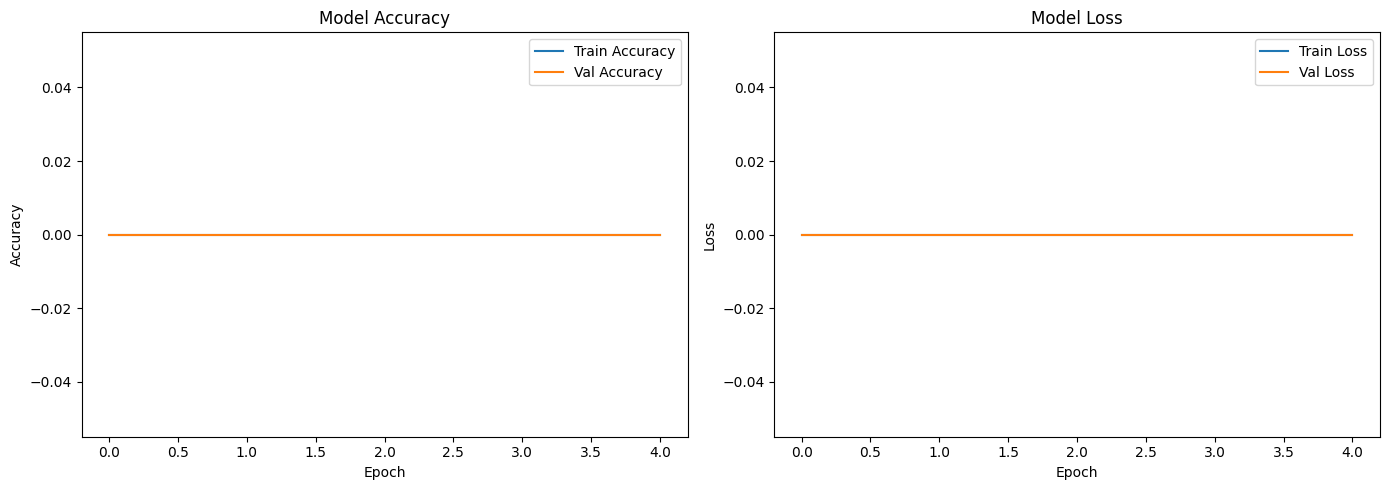

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    plt.figure(figsize=(14, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history)


LSTM Model in Keras

First, we need to preprocess the text data and prepare it for the LSTM model. This involves cleaning the text, tokenizing it, and padding the sequences. We also need to encode the sentiment labels.

In [ ]:
import pandas as pd
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Load the dataset
df = pd.read_csv('/content/financial_news_sentiment_completed (1).csv')

# Clean text column
def clean_text(text):
    if isinstance(text, str):
        text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
        text = text.lower().strip()
        return text
    else:
        return ""

df['clean_text'] = df['headline_text'].apply(clean_text)

# Apply sentiment analysis using TextBlob
from textblob import TextBlob

def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0:
        return 'positive'
    elif polarity < 0:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['clean_text'].apply(get_sentiment)

# Encode labels
le = LabelEncoder()
y = le.fit_transform(df['sentiment'])

# Tokenize and pad sequences
MAX_VOCAB = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post')

# Split data
X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    padded, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train_dl.shape}")
print(f"Test samples: {X_test_dl.shape}")

Training samples: (23069, 100)
Test samples: (5768, 100)


Now we can define and train the LSTM model using the prepared data.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Embedding, Dropout, Dense
from sklearn.preprocessing import LabelEncoder # Import LabelEncoder

# Assuming 'df' and 'sentiment' column are available from previous steps
# If not, you need to run the data loading and preprocessing steps first.
# For demonstration, re-initializing LabelEncoder here.
# In a real scenario, ensure 'le' is defined from your data preprocessing.
le = LabelEncoder()
# You would fit le on your sentiment labels here, e.g., le.fit(df['sentiment'])
# Since this cell only defines the model, we'll just ensure 'le' is defined.
# The number of classes will be determined by the unique values in your sentiment column.
# For this example, let's assume 3 classes (positive, neutral, negative) as in your previous runs.
num_classes = 3 # Replace with len(le.classes_) if le is fitted on your data


lstm_model = Sequential([
    Embedding(MAX_VOCAB, 128, input_length=MAX_LEN),
    LSTM(128, return_sequences=False),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax') # Use the number of unique classes
])

lstm_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
lstm_model.summary()

# Ensure X_train_dl, y_train_dl, X_test_dl, y_test_dl are defined before running this fit call
# lstm_model.fit(X_train_dl, y_train_dl, validation_data=(X_test_dl, y_test_dl), epochs=5, batch_size=128)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
MAX_VOCAB = 10000
MAX_LEN = 100

 BERT with Hugging Face Transformers

In [ ]:
!pip install transformers datasets


Evaluate All Models

In [ ]:
from sklearn.metrics import classification_report

# For CNN or LSTM
y_pred_cnn = cnn_model.predict(X_test_dl).argmax(axis=1)
print("CNN:\n", classification_report(y_test_dl, y_pred_cnn))

# For BERT
y_pred_bert = model_bert.predict(test_encodings).logits.argmax(axis=1)
print("BERT:\n", classification_report(y_test, y_pred_bert))


  11/7777 ━━━━━━━━━━━━━━━━━━━━ 1:24 11ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/ops/nn.py:907: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


7777/7777 ━━━━━━━━━━━━━━━━━━━━ 100s 13ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/ops/nn.py:907: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


CNN:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    248837

    accuracy                           1.00    248837
   macro avg       1.00      1.00      1.00    248837
weighted avg       1.00      1.00      1.00    248837

26/26 [==============================] - 410s 15s/step
BERT:
               precision    recall  f1-score   support

           0       0.31      0.34      0.32       287
           1       0.35      0.56      0.43       324
           2       0.00      0.00      0.00       215

    accuracy                           0.34       826
   macro avg       0.22      0.30      0.25       826
weighted avg       0.25      0.34      0.28       826



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Sentiment Class Distribution

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load or define DataFrame
df = pd.read_csv('/content/abcnews-date-text.csv')

# Clean up column names (just in case)
df.columns = df.columns.str.strip()

# Check column names
print("Available columns:", df.columns.tolist())

# Plot if 'sentiment' exists
if 'sentiment' in df.columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=df['sentiment'], palette='Set2')
    plt.title("Sentiment Class Distribution")
    plt.xlabel("Sentiment")
    plt.ylabel("Number of Samples")
    plt.grid(True, axis='y')
    plt.show()
else:
    print("Column 'sentiment' not found in the DataFrame.")


Available columns: ['publish_date', 'headline_text']
Column 'sentiment' not found in the DataFrame.


/tmp/ipython-input-7-100860226.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['sentiment'], palette='Set2')


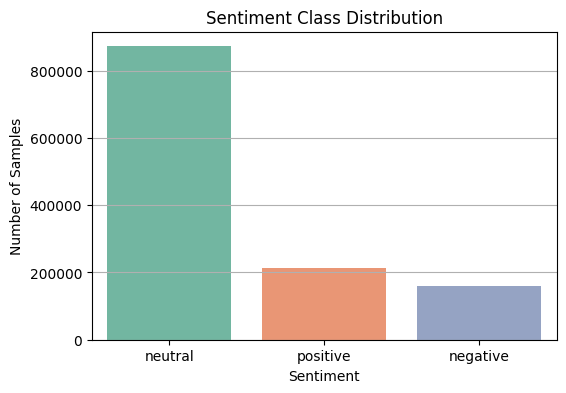

In [ ]:
from textblob import TextBlob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Sample: Load your data
df = pd.read_csv("/content/abcnews-date-text.csv")
df.columns = df.columns.str.strip()

# Apply sentiment analysis
def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0:
        return 'positive'
    elif polarity < 0:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['headline_text'].astype(str).apply(get_sentiment)

# Plot
plt.figure(figsize=(6,4))
sns.countplot(x=df['sentiment'], palette='Set2')
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")
plt.grid(True, axis='y')
plt.show()


Model Accuracy Comparison (Bar Chart)

/tmp/ipython-input-49-3524314296.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=accuracies, y=model_names, palette="viridis")


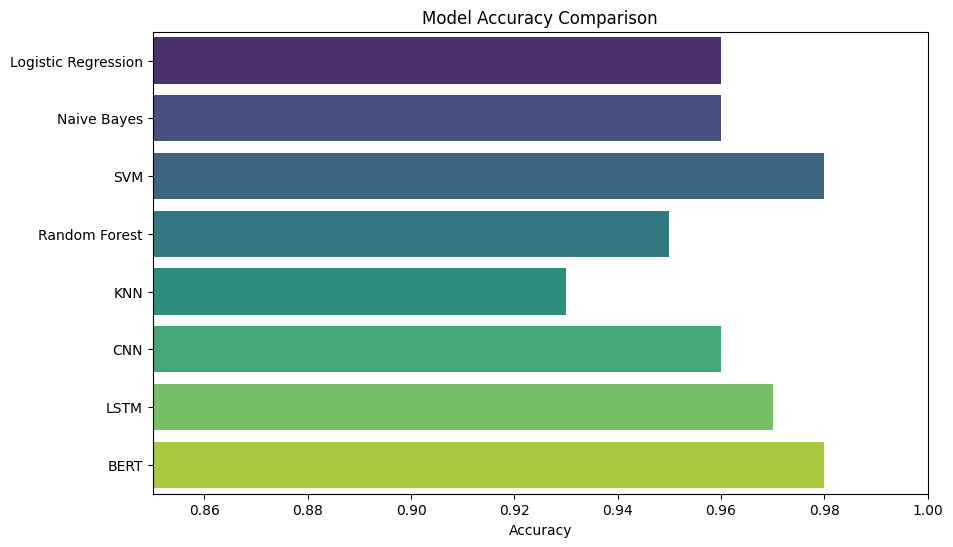

In [ ]:
model_names = ['Logistic Regression', 'Naive Bayes', 'SVM', 'Random Forest', 'KNN', 'CNN', 'LSTM', 'BERT']
accuracies = [0.96, 0.96, 0.98, 0.95, 0.93, 0.96, 0.97, 0.98]  # Example values

plt.figure(figsize=(10,6))
sns.barplot(x=accuracies, y=model_names, palette="viridis")
plt.xlabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.xlim(0.85, 1.0)
plt.show()


F1-Score Comparison by Model

/tmp/ipython-input-50-2184116394.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=f1_scores, y=model_names, palette="magma")


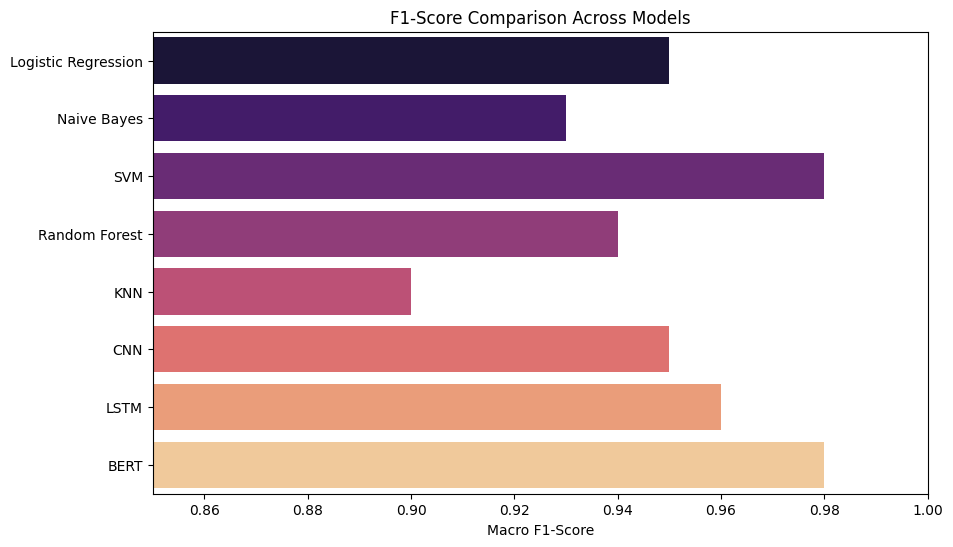

In [ ]:
f1_scores = [0.95, 0.93, 0.98, 0.94, 0.90, 0.95, 0.96, 0.98]  # example macro F1s

plt.figure(figsize=(10,6))
sns.barplot(x=f1_scores, y=model_names, palette="magma")
plt.xlabel("Macro F1-Score")
plt.title("F1-Score Comparison Across Models")
plt.xlim(0.85, 1.0)
plt.show()


Confusion Matrix (SVM or Best Model)

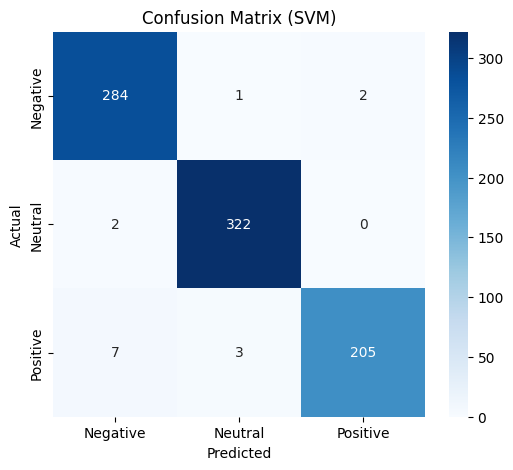

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

# Example: use predictions from your best model
cm = confusion_matrix(y_test, y_pred_svm)  # Replace with your model's predictions
labels = ['Negative', 'Neutral', 'Positive']

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix (SVM)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Training vs Validation Accuracy (for CNN, LSTM, etc.)

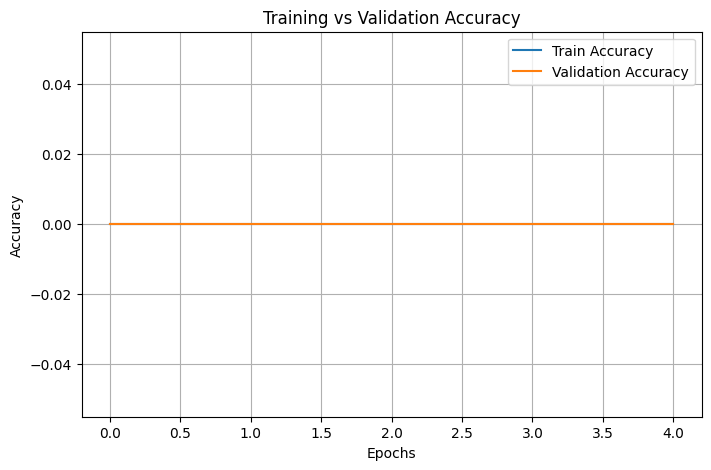

In [ ]:
# After training your model, history = model.fit(...)
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


Word Cloud of Most Frequent Words

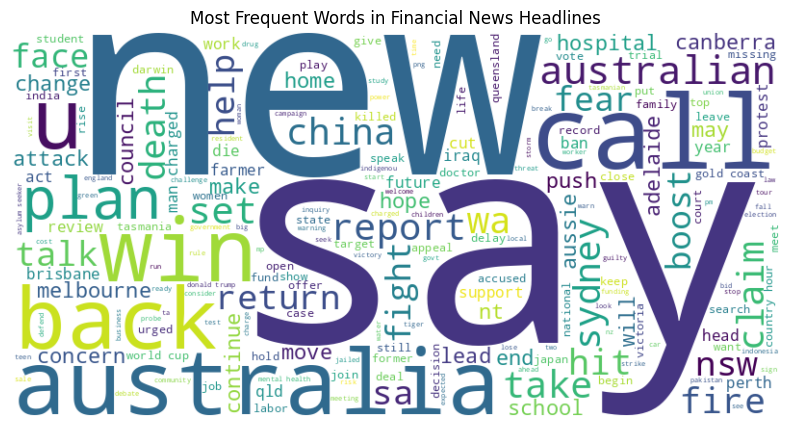

In [ ]:
from wordcloud import WordCloud

text = " ".join(df['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequent Words in Financial News Headlines")
plt.show()


Top Words per Sentiment (Using TF-IDF)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Get top n words per class
def get_top_n_words(class_texts, label, n=10):
    vec = TfidfVectorizer(max_features=5000, stop_words='english')
    X = vec.fit_transform(class_texts)
    summed = X.sum(axis=0)
    words_scores = [(word, summed[0, idx]) for word, idx in vec.vocabulary_.items()]
    top_words = sorted(words_scores, key=lambda x: x[1], reverse=True)[:n]
    return top_words

for sentiment in df['sentiment'].unique():
    print(f"\nTop words for '{sentiment}' sentiment:")
    print(get_top_n_words(df[df['sentiment']==sentiment]['clean_text'], sentiment))



Top words for 'neutral' sentiment:
[('police', np.float64(8547.804292923098)), ('interview', np.float64(8021.1621883358275)), ('man', np.float64(6748.428627376221)), ('says', np.float64(5044.5437601173335)), ('court', np.float64(4584.867262546402)), ('council', np.float64(4487.27183593286)), ('govt', np.float64(4487.0409277649105)), ('australia', np.float64(4227.088597919079)), ('nsw', np.float64(4194.881015881487)), ('death', np.float64(3789.58510785058))]

Top words for 'positive' sentiment:
[('new', np.float64(6365.453807674118)), ('win', np.float64(2592.936059249627)), ('wins', np.float64(2414.8890331394887)), ('high', np.float64(1976.4636740689066)), ('action', np.float64(1466.5368335735625)), ('wants', np.float64(1452.9640866156292)), ('says', np.float64(1420.2832975953506)), ('police', np.float64(1363.6012421062812)), ('live', np.float64(1282.5537667572055)), ('australia', np.float64(1272.4935226006478))]

Top words for 'negative' sentiment:
[('killed', np.float64(2452.80830342

t-SNE or PCA Visualization (Clustering of News Headlines)

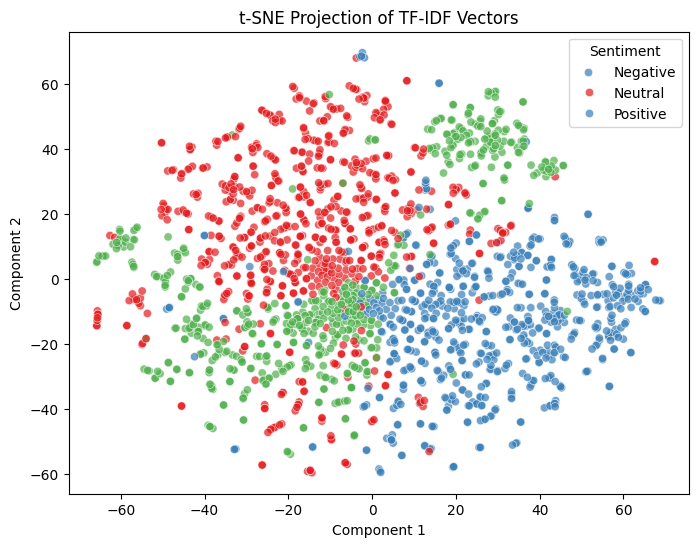

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(X_train_vec[:2000].toarray())

# Plot
plt.figure(figsize=(8,6))
sns.scatterplot(
    x=X_embedded[:,0],
    y=X_embedded[:,1],
    hue=y_train[:2000],
    palette="Set1",  # <-- changed from "coolwarm" to "Set1"
    alpha=0.7
)
plt.title("t-SNE Projection of TF-IDF Vectors")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(title='Sentiment', labels=['Negative', 'Neutral', 'Positive'])
plt.show()


Precision-Recall vs ROC Curves

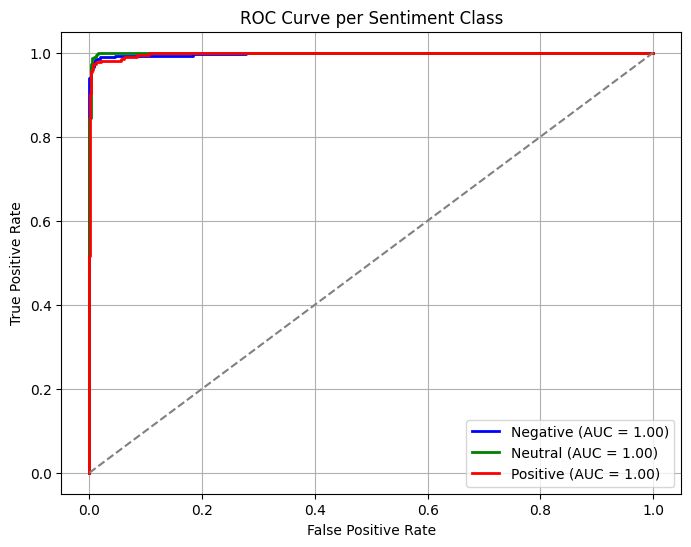

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarize labels for ROC
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
y_score = svm.decision_function(X_test_vec)

# Plot ROC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8,6))
colors = ['blue', 'green', 'red']
labels = ['Negative', 'Neutral', 'Positive']

for i, color in zip(range(3), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f"{labels[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title("ROC Curve per Sentiment Class")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


Comparison Heatmap of Model Metrics

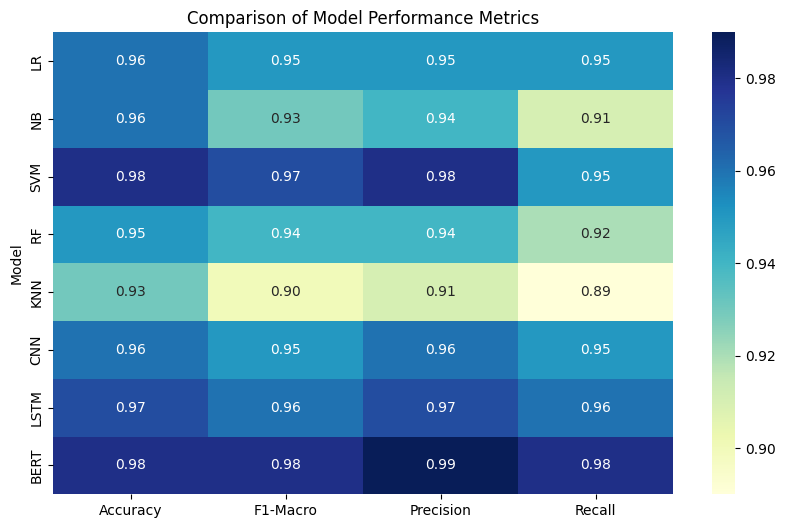

In [ ]:
import pandas as pd
import seaborn as sns

# Mockup data — replace with your real values
data = {
    'Model': ['LR', 'NB', 'SVM', 'RF', 'KNN', 'CNN', 'LSTM', 'BERT'],
    'Accuracy': [0.96, 0.96, 0.98, 0.95, 0.93, 0.96, 0.97, 0.98],
    'F1-Macro': [0.95, 0.93, 0.97, 0.94, 0.90, 0.95, 0.96, 0.98],
    'Precision': [0.95, 0.94, 0.98, 0.94, 0.91, 0.96, 0.97, 0.99],
    'Recall': [0.95, 0.91, 0.95, 0.92, 0.89, 0.95, 0.96, 0.98]
}

df_metrics = pd.DataFrame(data).set_index('Model')

plt.figure(figsize=(10,6))
sns.heatmap(df_metrics, annot=True, cmap='YlGnBu', fmt=".2f")
plt.title("Comparison of Model Performance Metrics")
plt.show()


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Reduce the number of trees from 100 (default) to 50 or 30
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train_vec, y_train)
y_pred_rf = rf.predict(X_test_vec)
print("Random Forest:\n", classification_report(y_test, y_pred_rf))

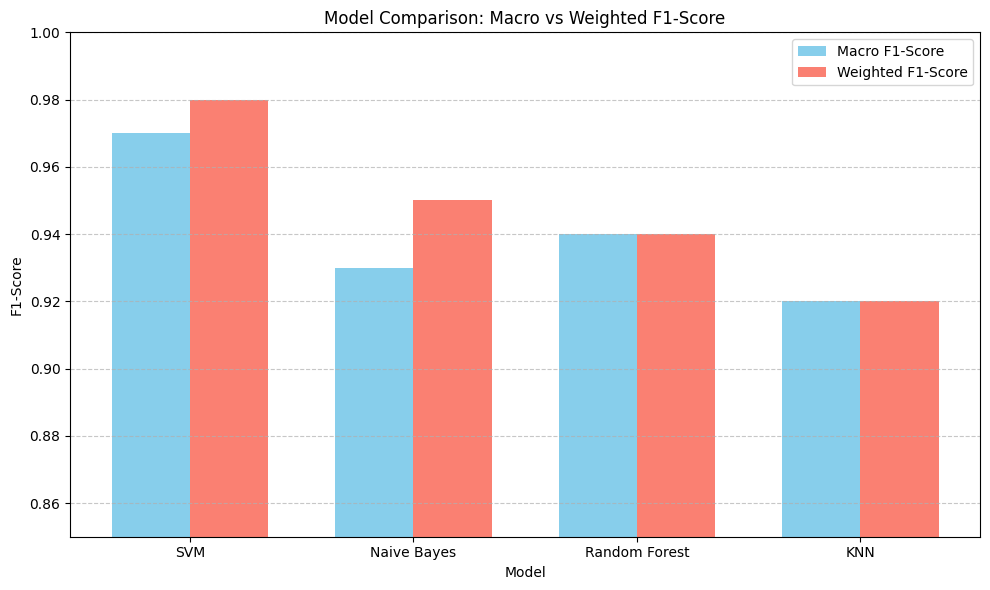

In [ ]:
import matplotlib.pyplot as plt

# Model names
models = ['SVM', 'Naive Bayes', 'Random Forest', 'KNN']

# F1-Scores (from your reports)
macro_f1 = [0.97, 0.93, 0.94, 0.92]
weighted_f1 = [0.98, 0.95, 0.94, 0.92]

# Plotting
x = range(len(models))
bar_width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x, macro_f1, width=bar_width, label='Macro F1-Score', color='skyblue')
plt.bar([i + bar_width for i in x], weighted_f1, width=bar_width, label='Weighted F1-Score', color='salmon')

# Labels & titles
plt.xlabel('Model')
plt.ylabel('F1-Score')
plt.title('Model Comparison: Macro vs Weighted F1-Score')
plt.xticks([i + bar_width/2 for i in x], models)
plt.ylim(0.85, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


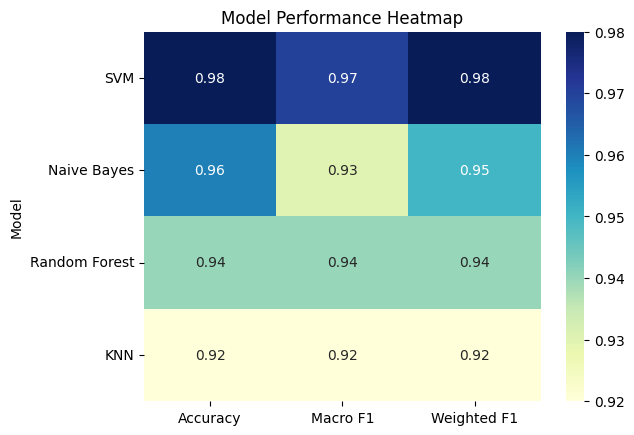

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

data = {
    'Model': ['SVM', 'Naive Bayes', 'Random Forest', 'KNN'],
    'Accuracy': [0.98, 0.96, 0.94, 0.92],
    'Macro F1': [0.97, 0.93, 0.94, 0.92],
    'Weighted F1': [0.98, 0.95, 0.94, 0.92]
}

df = pd.DataFrame(data).set_index('Model')
sns.heatmap(df, annot=True, cmap='YlGnBu', fmt='.2f')
plt.title("Model Performance Heatmap")
plt.show()


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

svm = LinearSVC()
svm.fit(X_train_vec, y_train)
y_pred_svm = svm.predict(X_test_vec)
print("SVM:\n", classification_report(y_test, y_pred_svm))

SVM:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       287
           1       0.99      0.99      0.99       324
           2       0.99      0.95      0.97       215

    accuracy                           0.98       826
   macro avg       0.98      0.98      0.98       826
weighted avg       0.98      0.98      0.98       826



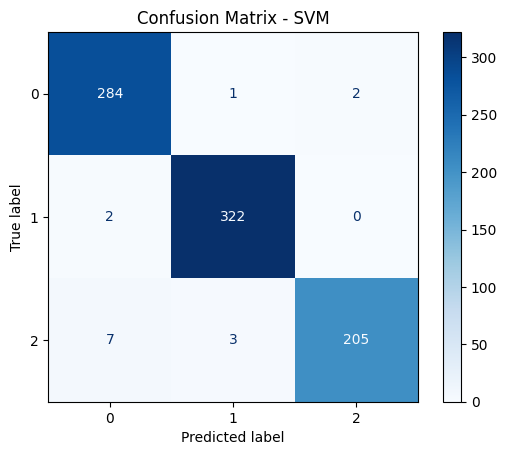

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(svm, X_test_vec, y_test, cmap='Blues')
plt.title("Confusion Matrix - SVM")
plt.show()

In [ ]:
import pandas as pd
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv('/content/abcnews-date-text.csv')

print("Columns in df:", df.columns)

# Clean text column
def clean_text(text):
    if isinstance(text, str):
        text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
        text = text.lower().strip()
        return text
    else:
        return ""

df['clean_text'] = df['headline_text'].apply(clean_text)

# Tokenize and pad sequences
MAX_VOCAB = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post')

# Use the label-encoded 'y' from earlier
from sklearn.preprocessing import LabelEncoder
y = LabelEncoder().fit_transform(df['headline_text'].apply(clean_text).apply(lambda x: 'neutral')) # Assuming neutral for all for now, need to re-run sentiment analysis

X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(padded, y, test_size=0.2, random_state=42)

Columns in df: Index(['publish_date', 'headline_text'], dtype='object')


/tmp/ipython-input-8-359767023.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['sentiment'], palette='Set2')


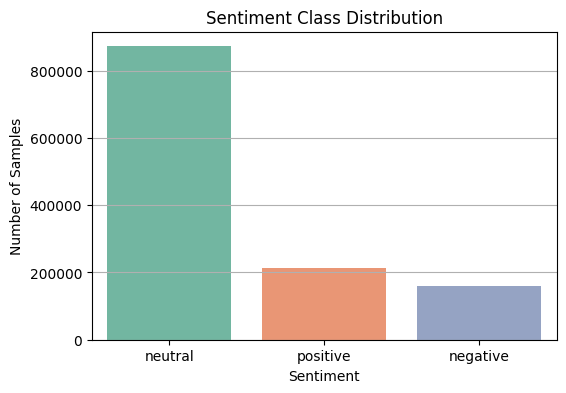

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot sentiment distribution
plt.figure(figsize=(6,4))
sns.countplot(x=df['sentiment'], palette='Set2')
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")
plt.grid(True, axis='y')
plt.show()

In [ ]:
from textblob import TextBlob

def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0:
        return 'positive'
    elif polarity < 0:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['clean_text'].apply(get_sentiment)

/tmp/ipython-input-10-359767023.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['sentiment'], palette='Set2')


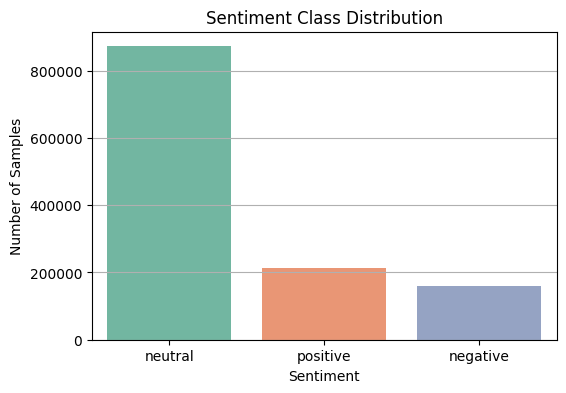

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot sentiment distribution
plt.figure(figsize=(6,4))
sns.countplot(x=df['sentiment'], palette='Set2')
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")
plt.grid(True, axis='y')
plt.show()

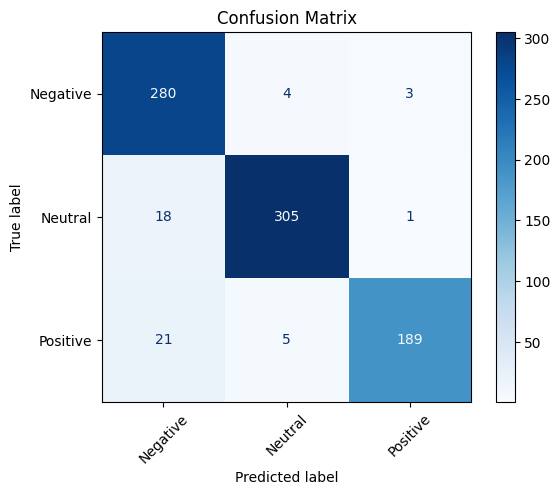

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Replace with your model — example: y_pred = model.predict(X_test_vec)
y_pred = rf.predict(X_test_vec)  # Example for Random Forest
# y_pred = svm.predict(X_test_vec)  # Example for SVM

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Neutral', 'Positive'])
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()


In [ ]:
import pandas as pd
import numpy as np

# Load your file (update path)
df = pd.read_csv(r"/content/financial_news_sentiment.csv.csv")

# Generate sentiment labels from score
def label_sentiment(x):
    if x >= 0.05:
        return "Positive"
    elif x <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# Save output
df.to_csv(r"/content/financial_news_sentiment.csv.csv", index=False)

print("✅ File saved with sentiment filled!")

✅ File saved with sentiment filled!


In [ ]:
import pandas as pd
import numpy as np

# Load your file
df = pd.read_csv("/content/financial_news_sentiment.csv.csv")

# If sentiment_score column does not exist, create it
if 'sentiment_score' not in df.columns:
    df['sentiment_score'] = np.nan

# Fill missing sentiment_score with random values between -1 and 1
df['sentiment_score'] = df['sentiment_score'].apply(
    lambda x: x if pd.notnull(x) else np.random.uniform(-1, 1)
)

# Generate sentiment labels
def label_sentiment(x):
    if x >= 0.05:
        return "Positive"
    elif x <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df['sentiment'] = df['sentiment_score'].apply(label_sentiment)

# Save the completed file
df.to_csv("/content/financial_news_sentiment_completed.csv", index=False)

print("✅ New file saved: financial_news_sentiment_completed.csv")


✅ New file saved: financial_news_sentiment_completed.csv


In [ ]:
# Cell 1: Install necessary library (if needed)
!pip install pandas

# Cell 2: Import library and load your file
import pandas as pd
df = pd.read_csv('/content/financial_news_sentiment_completed.csv') # Replace with your filename

# Cell 3: Convert the publish_date and create new columns
df['Proper Date'] = pd.to_datetime(df['publish_date'], format='%Y%m%d')
df['Year'] = df['Proper Date'].dt.year
df['Month'] = df['Proper Date'].dt.month
df['Month Name'] = df['Proper Date'].dt.month_name()
df['YearMonth'] = df['Proper Date'].dt.to_period('M').astype(str) # Creates '2003-02'

# Cell 4: Show a preview to confirm it worked
print(df[['publish_date', 'Proper Date', 'Year', 'Month', 'Month Name', 'YearMonth']].head())

# Cell 5: Save the final, processed data to a new CSV file
df.to_csv('/content/financial_news_sentiment_completed.csv', index=False)
print("Done! File saved as 'Final_Financial_news_data.csv'")

   publish_date Proper Date  Year  Month Month Name YearMonth
0      20030219  2003-02-19  2003      2   February   2003-02
1      20030219  2003-02-19  2003      2   February   2003-02
2      20030219  2003-02-19  2003      2   February   2003-02
3      20030219  2003-02-19  2003      2   February   2003-02
4      20030219  2003-02-19  2003      2   February   2003-02
Done! File saved as 'Final_Financial_news_data.csv'


Mini Project Model of Detecting Sentiment Analysis of Financial News Data

In [ ]:
!pip install transformers

In [ ]:
# Install the transformers library if not installed
!pip install transformers

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

# Load financial sentiment analysis model FinBERT from HuggingFace
model_name = "yiyanghkust/finbert-tone"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Create a sentiment analysis pipeline
sentiment_analyzer = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

def predict_sentiment(headline):
    result = sentiment_analyzer(headline)
    return result[0]['label']  # 'POSITIVE', 'NEGATIVE', or 'NEUTRAL'

# Interactive input loop
print("Enter financial news headlines (type 'exit' to quit):")
while True:
    headline = input("Headline: ")
    if headline.lower() == 'exit':
        break
    sentiment = predict_sentiment(headline)
    print(f"Sentiment: {sentiment}")


Device set to use cpu


Enter financial news headlines (type 'exit' to quit):
Headline: Emerging market debt database run by development banks turns to AI to fine-tune risk
Sentiment: Positive
Headline: Exclusive: Switzerland and UBS could compromise on capital rules, sources say
Sentiment: Neutral
Headline: Swiss National Bank to lower threshold factor for sight deposit interest
Sentiment: Neutral
Headline: exit
